# Bài 3 — Phát hiện biên và phân ngưỡng

Các kết quả được lưu vào `outputs/bai_3/`. Tham số hiển thị trong tiêu đề hình; kết luận cần dựa trên kết quả thực tế.


In [1]:
from pathlib import Path
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_otsu
ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "data").is_dir():
    raise FileNotFoundError("Run from repository root or notebooks/")
sys.path.insert(0, str(ROOT))
from src.edge_and_threshold import compute_sobel, compute_laplacian, my_otsu_threshold, run_adaptive_threshold
data = ROOT / "data" / "DIP3E_Original_Images_CH10"
names = {
    "building": "Fig1016(a)(building_original).tif",
    "polymersomes": "Fig1039(a)(polymersomes).tif",
    "shaded": "Fig1049(a)(spot_shaded_text_image).tif",
    "clean": "Fig1036(a)(original_septagon).tif",
    "std10": "Fig1036(b)(gaussian_noise_mean_0_std_10_added).tif",
    "std50": "Fig1036(c)(gaussian_noise_mean_0_std_50_added).tif",
}
images = {}
for name, file in names.items():
    image = cv2.imread(str(data / file), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(data / file)
    images[name] = image
    print(name, file, image.shape, image.dtype)
OUT = ROOT / "outputs" / "bai_3"
def figure(folder, filename, panels, titles, cols=4):
    path = OUT / folder
    path.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots((len(panels)+cols-1)//cols, cols, figsize=(3.5*cols, 3.5*((len(panels)+cols-1)//cols)), squeeze=False)
    for ax, image, title in zip(axes.flat, panels, titles):
        ax.imshow(image, cmap="gray")
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    for ax in axes.flat[len(panels):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(path / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


building Fig1016(a)(building_original).tif (834, 1114) uint8
polymersomes Fig1039(a)(polymersomes).tif (648, 702) uint8
shaded Fig1049(a)(spot_shaded_text_image).tif (686, 772) uint8
clean Fig1036(a)(original_septagon).tif (651, 814) uint8
std10 Fig1036(b)(gaussian_noise_mean_0_std_10_added).tif (651, 814) uint8
std50 Fig1036(c)(gaussian_noise_mean_0_std_50_added).tif (651, 814) uint8


## 1. Sobel, Laplacian và Canny

Sobel được chia theo hệ số chuẩn của kernel trước khi dùng ngưỡng cố định. Laplacian hiển thị độ lớn phản hồi; Canny được làm trơn Gaussian tường minh trước khi tính.


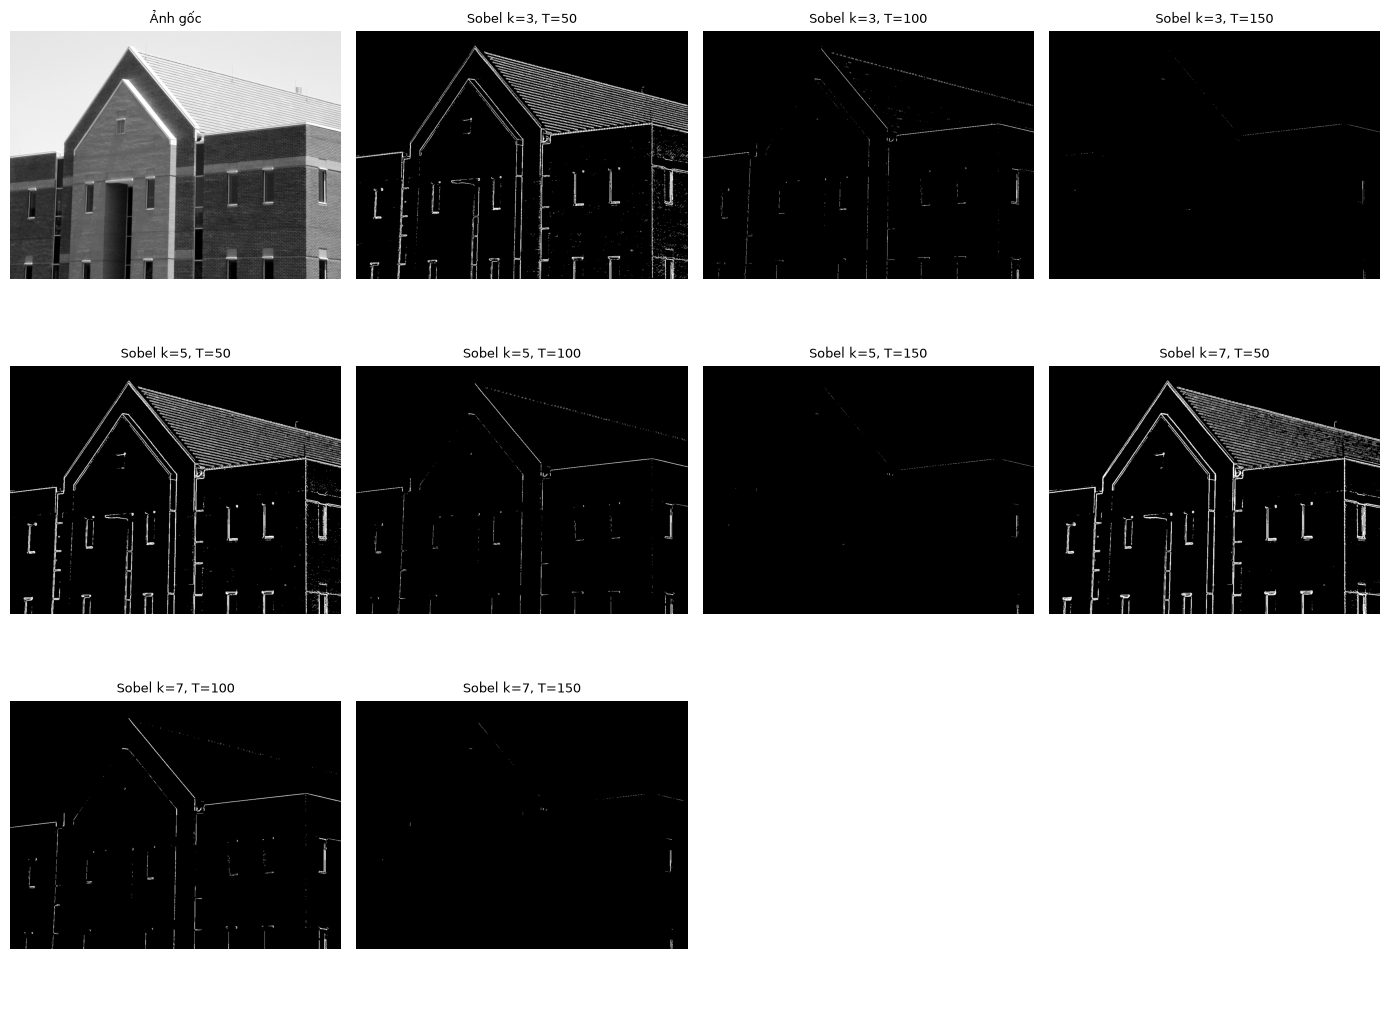

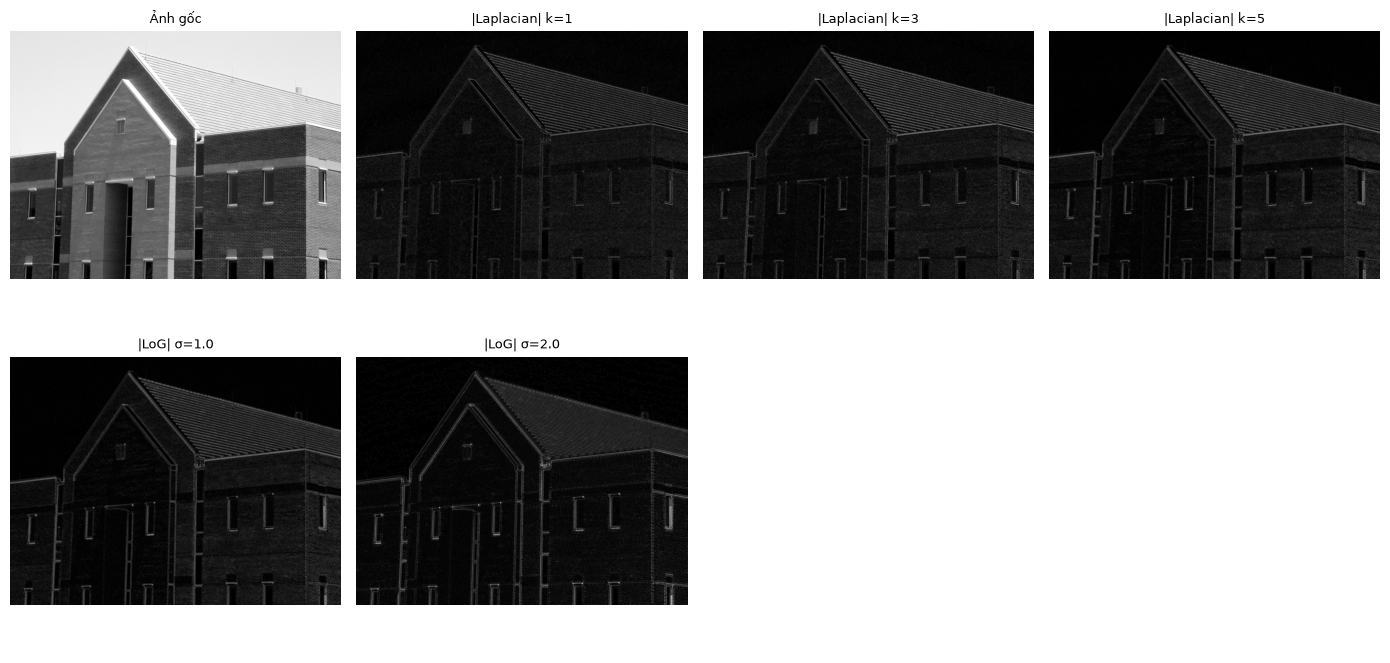

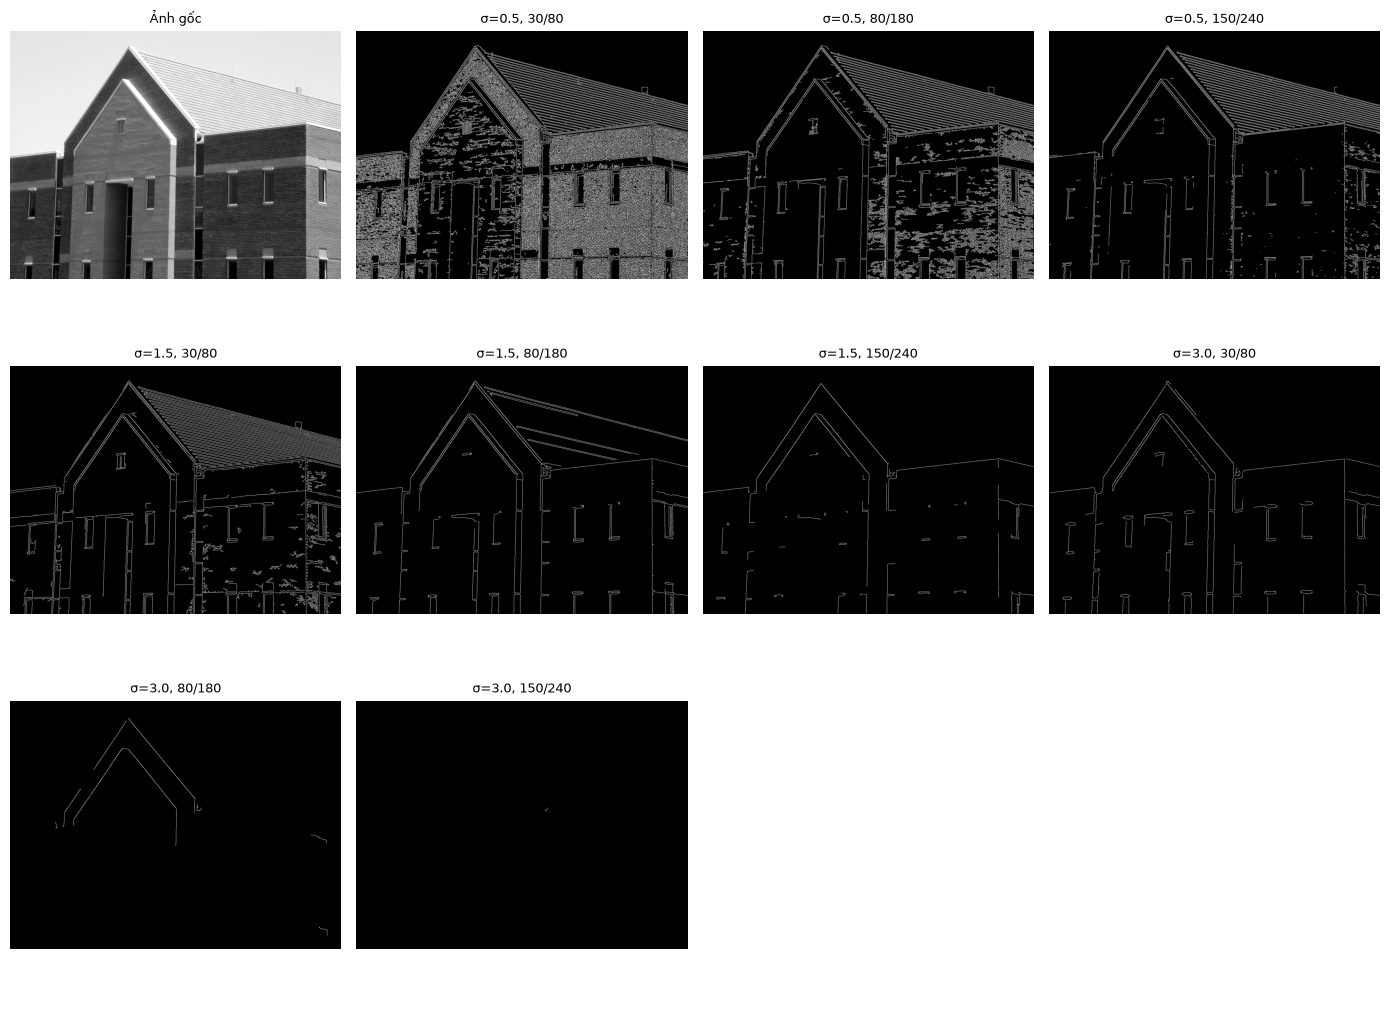

In [2]:
building = images["building"]
panels, titles = [building], ["Ảnh gốc"]
for k in (3, 5, 7):
    raw = compute_sobel(building, k)["magnitude"]
    kx, ky = cv2.getDerivKernels(1, 0, k, normalize=False)
    gain = float(np.sum(kx[kx > 0]) * np.sum(ky))
    normalized = raw / gain
    for threshold in (50, 100, 150):
        panels.append((normalized > threshold).astype(np.uint8)*255)
        titles.append(f"Sobel k={k}, T={threshold}")
figure("3.1_edge_detection", "3.1_building_input_vs_output_sobel_survey.png", panels, titles)
panels, titles = [building], ["Ảnh gốc"]
for k in (1, 3, 5):
    panels.append(np.abs(compute_laplacian(building, k)))
    titles.append(f"|Laplacian| k={k}")
for sigma in (1.0, 2.0):
    panels.append(np.abs(compute_laplacian(building, 3, sigma)))
    titles.append(f"|LoG| σ={sigma}")
figure("3.1_edge_detection", "3.1_building_input_vs_output_laplacian_log.png", panels, titles)
panels, titles = [building], ["Ảnh gốc"]
for sigma in (.5, 1.5, 3.0):
    blur = cv2.GaussianBlur(building, (0, 0), sigma)
    for low, high in ((30,80),(80,180),(150,240)):
        panels.append(cv2.Canny(blur, low, high))
        titles.append(f"σ={sigma}, {low}/{high}")
figure("3.1_edge_detection", "3.1_building_input_vs_output_canny_survey.png", panels, titles)


## 2. Otsu và phân ngưỡng thích nghi

Otsu chọn ngưỡng nhỏ nhất khi các ngưỡng cùng cho phương sai cực đại. Mask dùng điều kiện pixel > T.


Otsu NumPy: 181 OpenCV: 181.0 scikit-image: 181 pixel khác OpenCV: 0


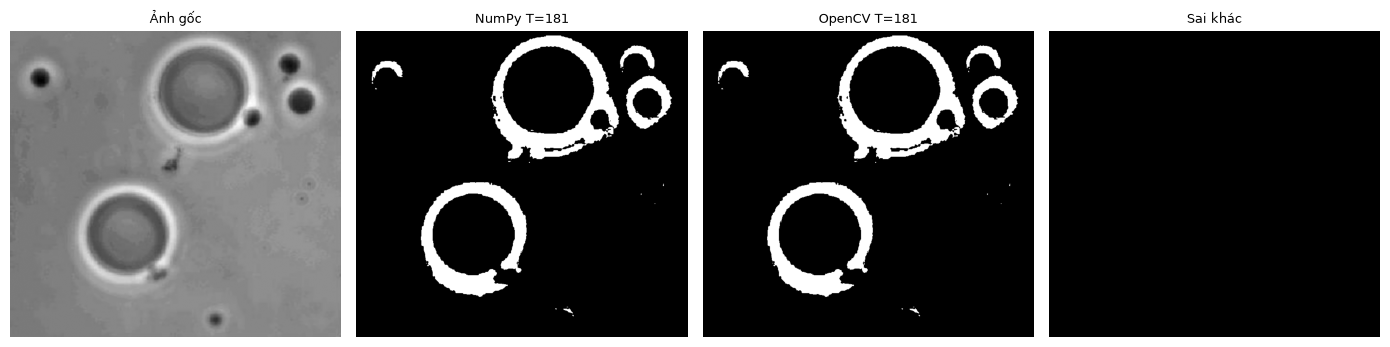

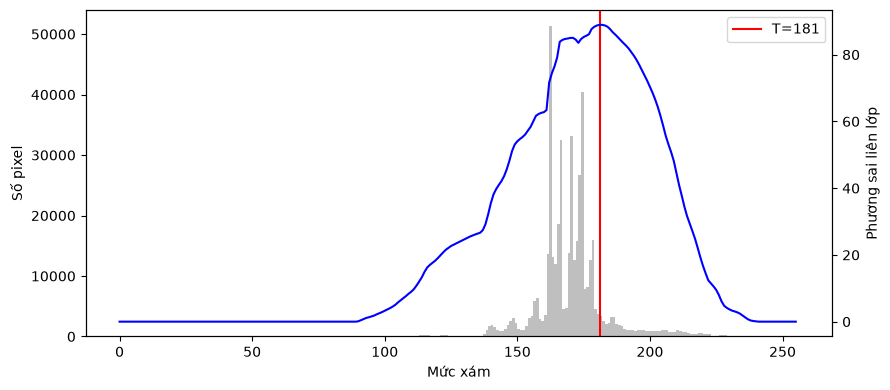

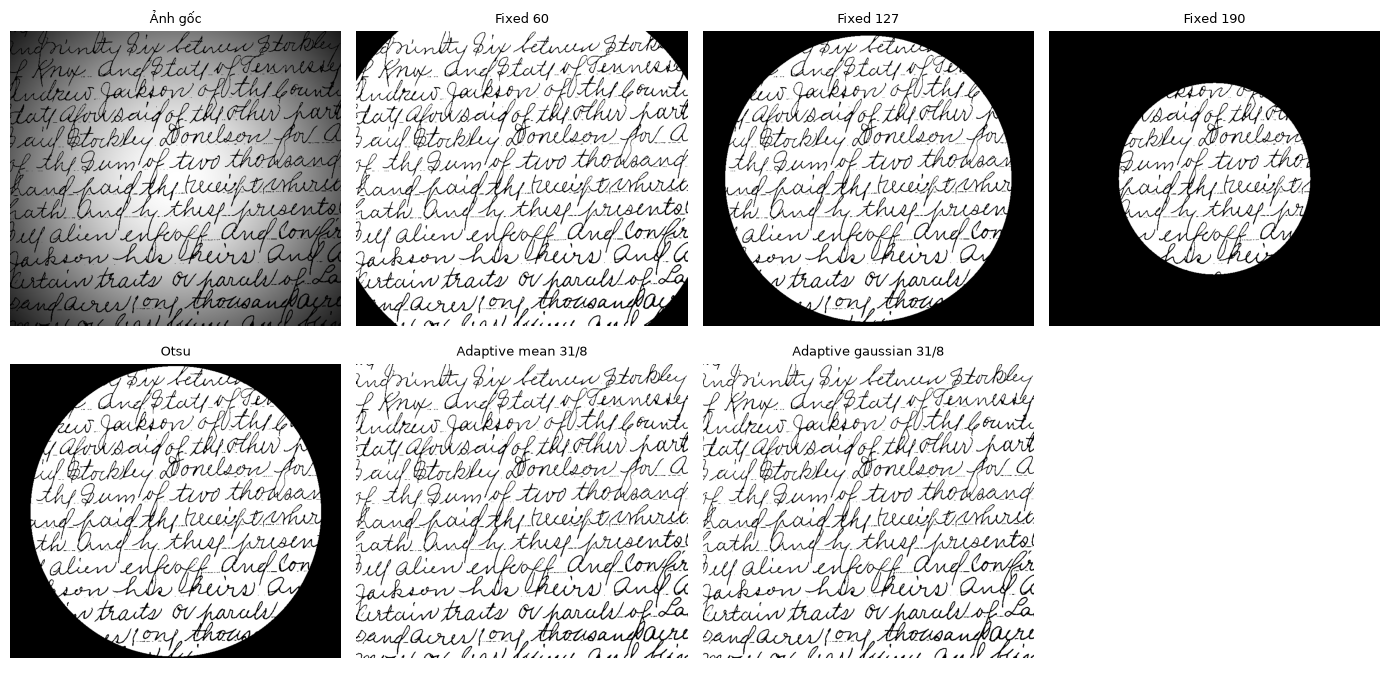

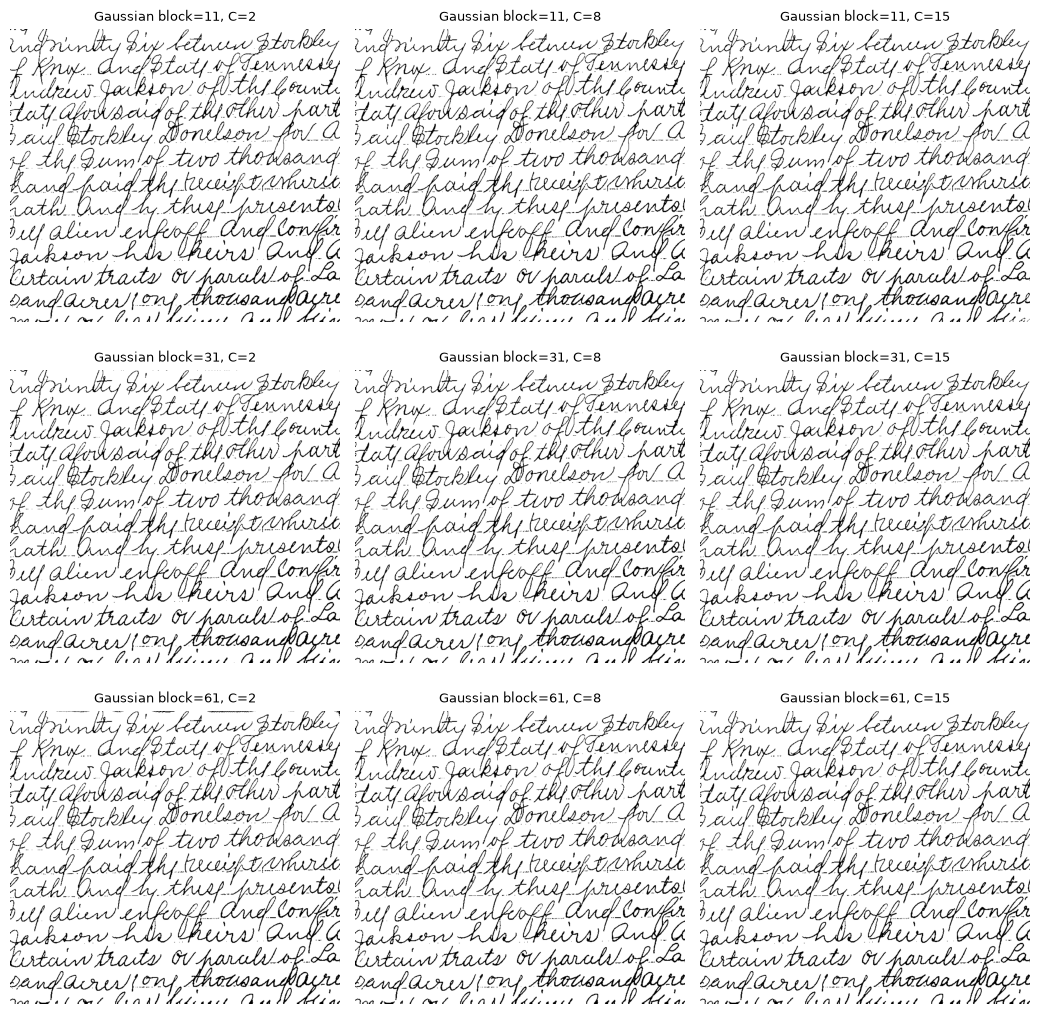

In [3]:
poly = images["polymersomes"]
threshold, variance, curve, mask = my_otsu_threshold(poly)
cv_t, cv_mask = cv2.threshold(poly, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
sk_t = threshold_otsu(poly)
print("Otsu NumPy:", threshold, "OpenCV:", cv_t, "scikit-image:", sk_t,
      "pixel khác OpenCV:", np.count_nonzero(mask != cv_mask))
figure("3.2_thresholding", "3.2_polymersomes_input_vs_output_my_otsu_verification.png",
       [poly, mask, cv_mask, cv2.absdiff(mask, cv_mask)],
       ["Ảnh gốc", f"NumPy T={threshold}", f"OpenCV T={cv_t:g}", "Sai khác"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(poly.ravel(), bins=256, range=(0,256), color="gray", alpha=.5)
ax.set_xlabel("Mức xám"); ax.set_ylabel("Số pixel"); ax.axvline(threshold, color="red", label=f"T={threshold}")
other = ax.twinx(); other.plot(curve, color="blue"); other.set_ylabel("Phương sai liên lớp")
ax.legend()
fig.tight_layout(); fig.savefig(OUT / "3.2_thresholding" / "3.2_polymersomes_histogram_otsu.png", dpi=150); plt.show(); plt.close(fig)
text = images["shaded"]
_, _, _, otsu_mask = my_otsu_threshold(text)
panels = [text] + [cv2.threshold(text, t, 255, cv2.THRESH_BINARY)[1] for t in (60,127,190)] + [otsu_mask]
titles = ["Ảnh gốc", "Fixed 60", "Fixed 127", "Fixed 190", "Otsu"]
for method in ("mean", "gaussian"):
    panels.append(run_adaptive_threshold(text, 31, 8, method))
    titles.append(f"Adaptive {method} 31/8")
figure("3.2_thresholding", "3.2_shaded_text_input_vs_output_fixed_vs_otsu_vs_adaptive.png", panels, titles)
panels, titles = [], []
for block in (11,31,61):
    for c in (2,8,15):
        panels.append(run_adaptive_threshold(text, block, c, "gaussian"))
        titles.append(f"Gaussian block={block}, C={c}")
figure("3.2_thresholding", "3.2_shaded_text_input_vs_output_adaptive_params_survey.png", panels, titles, 3)


## 3. Ảnh hưởng của nhiễu

Mask đa giác từ ảnh sạch là tham chiếu. Nhiễu muối tiêu được sinh từ seed 42; dùng Gaussian cho nhiễu Gaussian và median cho muối tiêu.


clean trực tiếp T= 76 IoU= 1.0 sai khác= 0
clean lọc T= 119 IoU= 1.0 sai khác= 4
std10 trực tiếp T= 125 IoU= 1.0 sai khác= 4
std10 lọc T= 126 IoU= 1.0 sai khác= 7
std50 trực tiếp T= 118 IoU= 0.6301 sai khác= 90264
std50 lọc T= 126 IoU= 0.9969 sai khác= 532
salt_pepper trực tiếp T= 76 IoU= 0.9275 sai khác= 13263


salt_pepper lọc T= 76 IoU= 0.9991 sai khác= 159


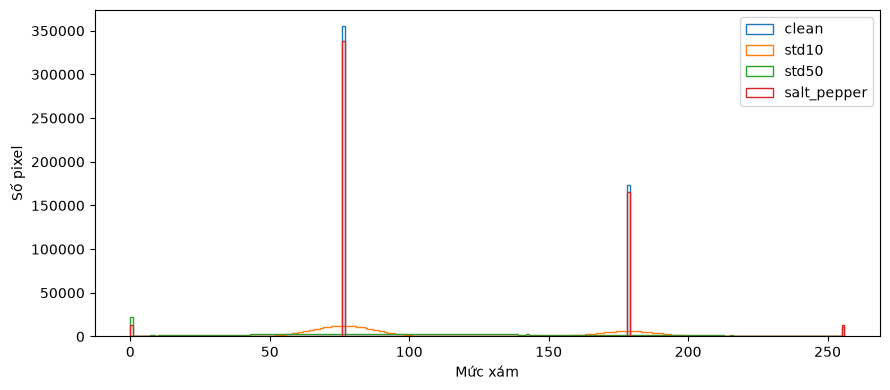

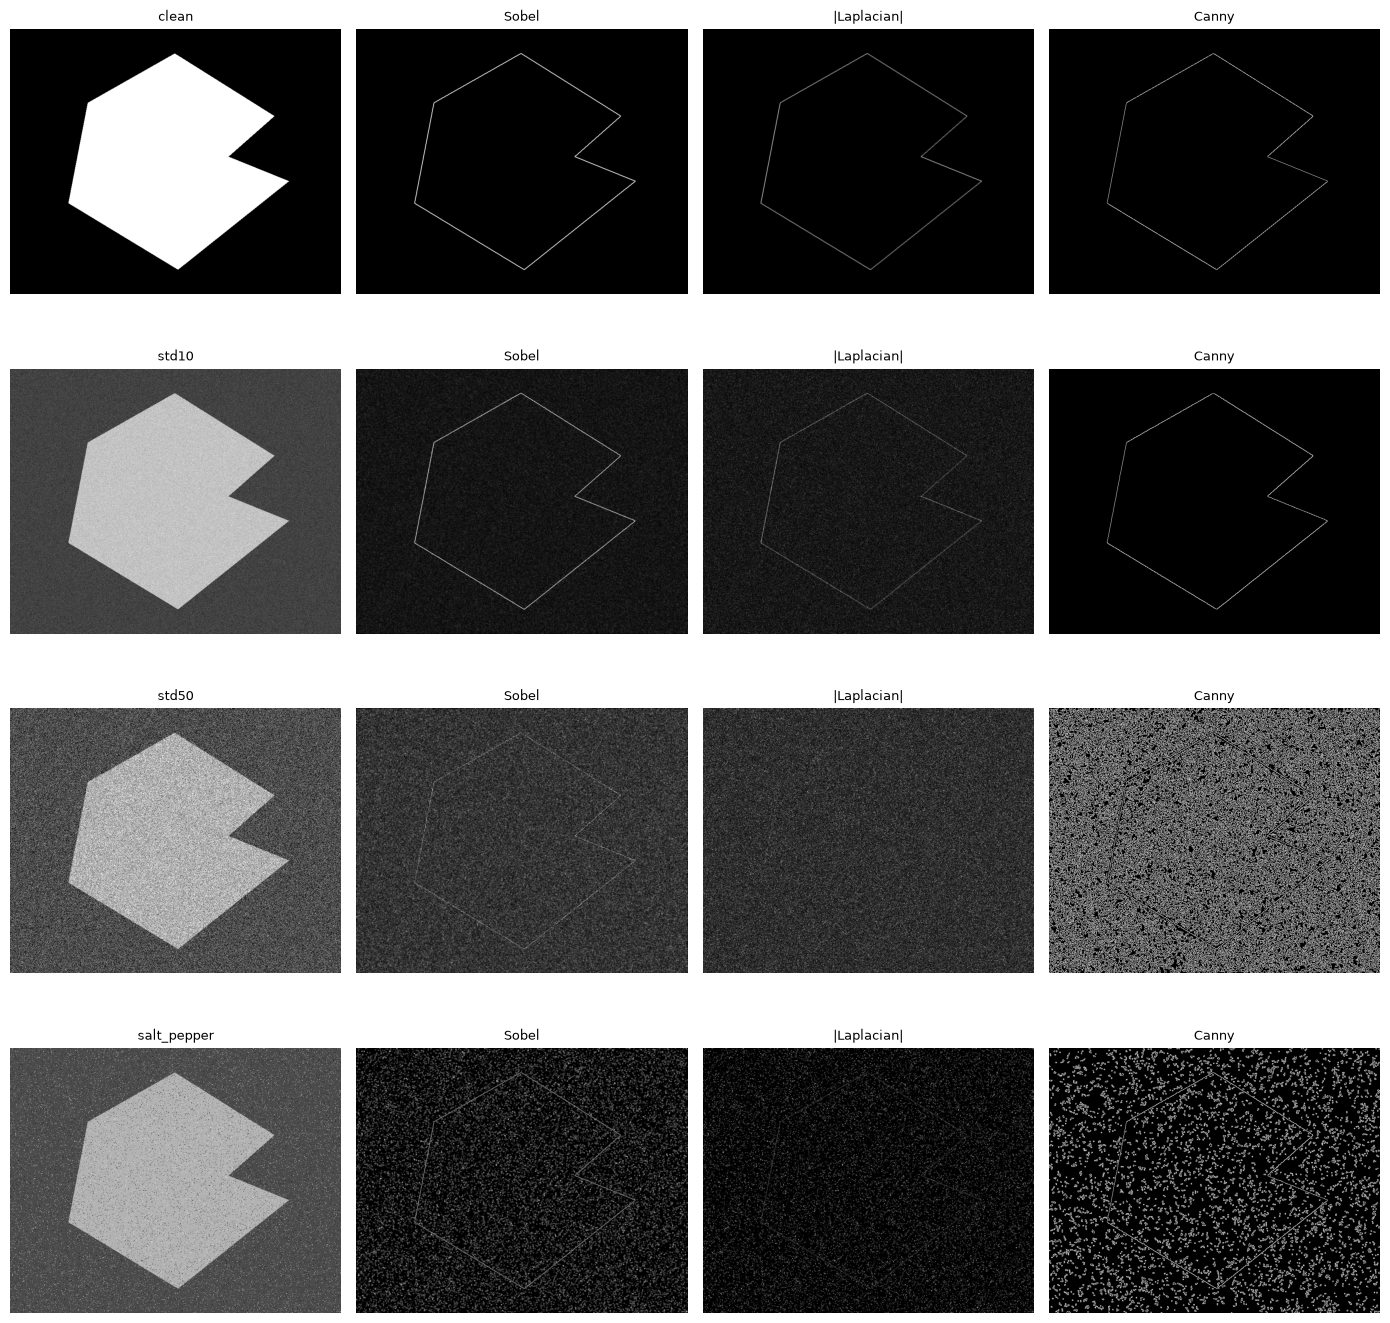

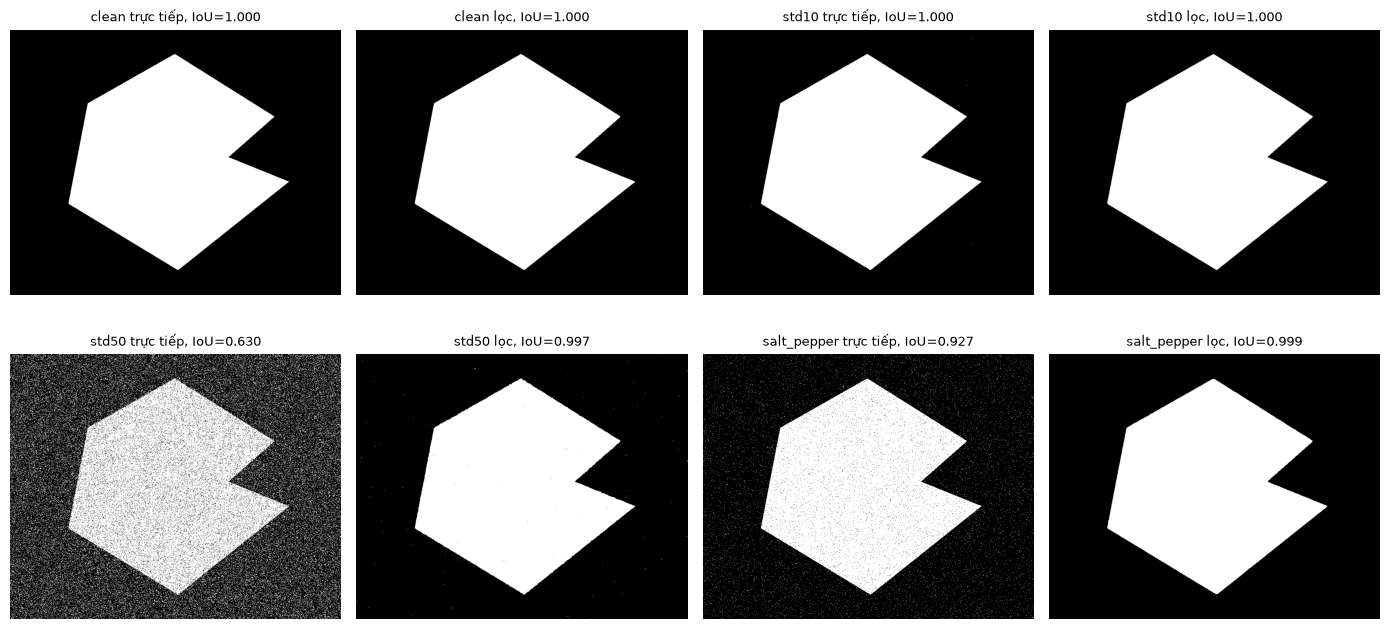

In [4]:
clean = images["clean"]
rng = np.random.default_rng(42)
random_values = rng.random(clean.shape)
salt = clean.copy()
salt[random_values < .025] = 0
salt[random_values > .975] = 255
cases = {"clean":clean, "std10":images["std10"], "std50":images["std50"], "salt_pepper":salt}
reference = clean > 127
edge_panels, edge_titles, mask_panels, mask_titles = [], [], [], []
fig, ax = plt.subplots(figsize=(9,4))
for name, image in cases.items():
    ax.hist(image.ravel(), bins=256, range=(0,256), histtype="step", label=name)
    sobel = compute_sobel(image, 3)["magnitude"] / 4
    lap = np.abs(compute_laplacian(image, 3))
    canny = cv2.Canny(cv2.GaussianBlur(image, (5,5), 1), 50, 150)
    edge_panels.extend([image, sobel, lap, canny])
    edge_titles.extend([name, "Sobel", "|Laplacian|", "Canny"])
    filtered = cv2.medianBlur(image, 5) if name == "salt_pepper" else cv2.GaussianBlur(image, (5,5), 1)
    for variant, candidate in (("trực tiếp", image), ("lọc", filtered)):
        t, _, _, mask = my_otsu_threshold(candidate)
        predicted = mask != 0
        union = np.count_nonzero(reference | predicted)
        iou = np.count_nonzero(reference & predicted) / union if union else 1.0
        print(name, variant, "T=", t, "IoU=", round(iou,4), "sai khác=", np.count_nonzero(reference != predicted))
        mask_panels.append(mask); mask_titles.append(f"{name} {variant}, IoU={iou:.3f}")
ax.legend(); ax.set_xlabel("Mức xám"); ax.set_ylabel("Số pixel")
folder=OUT / "3.3_noise_impact"; folder.mkdir(parents=True, exist_ok=True)
fig.tight_layout(); fig.savefig(folder / "3.3_histograms.png", dpi=150); plt.show(); plt.close(fig)
figure("3.3_noise_impact", "3.3_septagon_input_vs_output_edges_under_noise.png", edge_panels, edge_titles)
figure("3.3_noise_impact", "3.3_septagon_input_vs_output_otsu_under_noise_and_denoised.png", mask_panels, mask_titles)


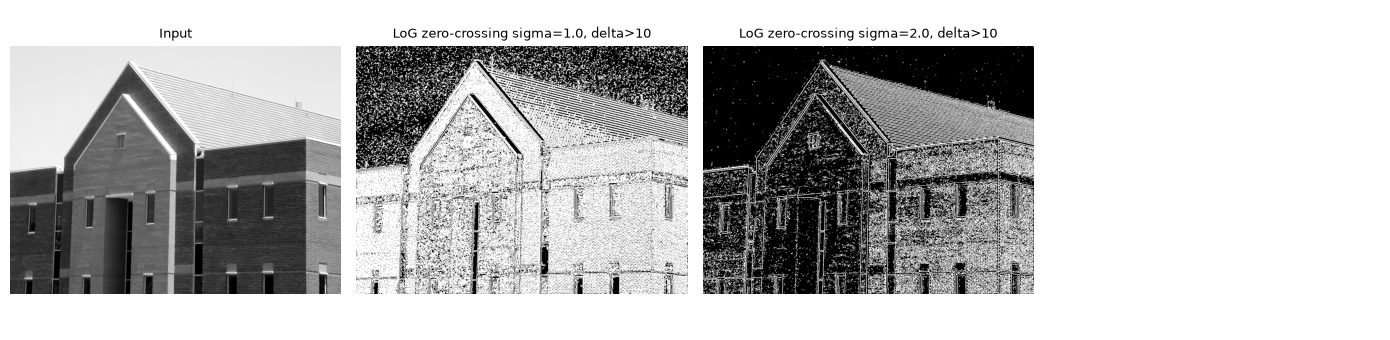

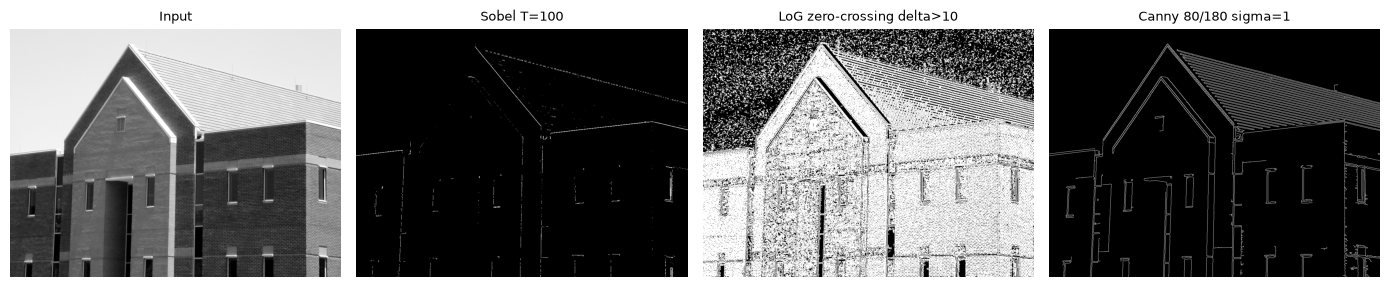

In [5]:
def zero_crossing(response, threshold):
    high = cv2.dilate(response, np.ones((3,3), np.uint8))
    low = cv2.erode(response, np.ones((3,3), np.uint8))
    return ((low < 0) & (high > 0) & ((high-low) > threshold)).astype(np.uint8)*255
panels=[building]; titles=["Input"]
for sigma in (1.0,2.0):
    response=compute_laplacian(building,3,sigma)
    panels.append(zero_crossing(response,10))
    titles.append(f"LoG zero-crossing sigma={sigma}, delta>10")
figure("3.1_edge_detection","3.1_building_log_zero_crossing.png",panels,titles)
sobel=compute_sobel(building,3)["magnitude"]/4
lap=compute_laplacian(building,3,1.0)
canny=cv2.Canny(cv2.GaussianBlur(building,(0,0),1.0),80,180)
figure("3.1_edge_detection","3.1_building_input_vs_output_compare_3_methods.png",
       [building,(sobel>100).astype(np.uint8)*255,zero_crossing(lap,10),canny],
       ["Input","Sobel T=100","LoG zero-crossing delta>10","Canny 80/180 sigma=1"])


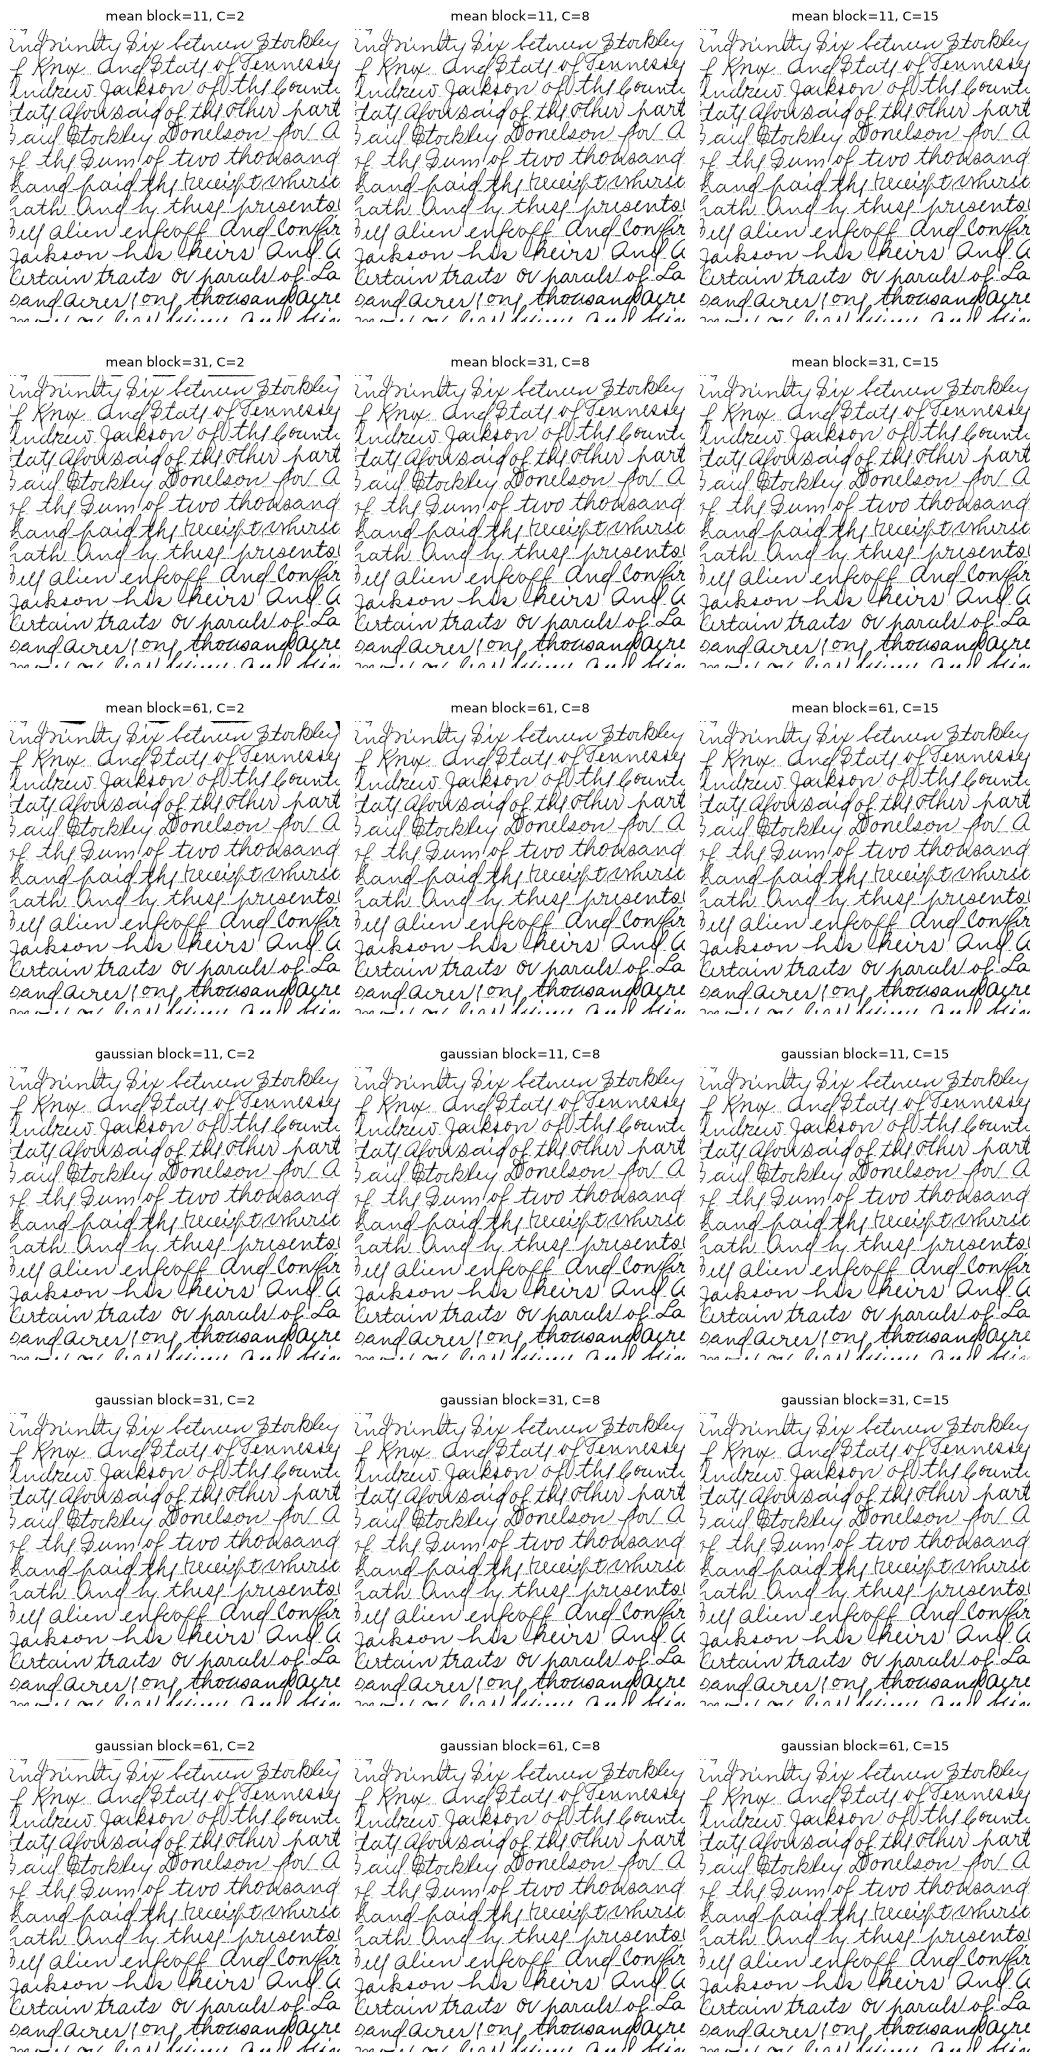

In [6]:
panels=[]; titles=[]
for method in ("mean","gaussian"):
    for block in (11,31,61):
        for c in (2,8,15):
            panels.append(run_adaptive_threshold(text,block,c,method))
            titles.append(f"{method} block={block}, C={c}")
figure("3.2_thresholding","3.2_shaded_text_adaptive_all_params.png",panels,titles,3)


Dùng biểu đồ, mask và IoU đã đo để viết nhận xét. Đối chiếu cùng ảnh và các tham số nêu trong hình; bổ sung ảnh chụp màn hình cá nhân khi nộp báo cáo.
